![](img/logoitqv1.jpg)

# Programa1.Normalización

![](img/python_logo.png)



*Francisco Escobar*

**Repositorio:** [GitHub](https://github.com/Franciscoe1/PracticaML.git)

# Caso Práctico: Neurona de McCulloch y Pitts

2. Aplicando la MPNeurona en caso práctico real

## 2.1. Conjunto de datos

Esta es una copia de los conjuntos de datos de UCI ML Breast Cancer Wisconsin: https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic

### Descripción de la muestra

Las características de entrada se calculan a partir de una imagen digitalizada de un aspirado de aguja fina (FNA) de una masa mamaria. Describen las características de los núcleos celulares presentes en la imagen.

El plano de separación descrito anteriormente se obtuvo utilizando el método de árbol de múltiples superficies (MSM-T) ["Construcción de un árbol de decisión mediante programación lineal"].

El programa lineal utilizado para obtener el plano de separación en el espacio tridimensional es el que se describe en [K.P. Bennett y O.L. Mangasarian].


## Lectura de datos


In [2]:
from sklearn.datasets import load_breast_cancer
cancer_name = load_breast_cancer()
# Separamos los datos de entrada y los datos de salida
X = cancer_name.data
Y = cancer_name.target


In [3]:
dir(cancer_name)


['DESCR',
 'data',
 'data_module',
 'feature_names',
 'filename',
 'frame',
 'target',
 'target_names']

In [4]:
print(X)


[[1.799e+01 1.038e+01 1.228e+02 ... 2.654e-01 4.601e-01 1.189e-01]
 [2.057e+01 1.777e+01 1.329e+02 ... 1.860e-01 2.750e-01 8.902e-02]
 [1.969e+01 2.125e+01 1.300e+02 ... 2.430e-01 3.613e-01 8.758e-02]
 ...
 [1.660e+01 2.808e+01 1.083e+02 ... 1.418e-01 2.218e-01 7.820e-02]
 [2.060e+01 2.933e+01 1.401e+02 ... 2.650e-01 4.087e-01 1.240e-01]
 [7.760e+00 2.454e+01 4.792e+01 ... 0.000e+00 2.871e-01 7.039e-02]]


## Visualización del conjunto de datos


In [5]:
import pandas as pd
df = pd.DataFrame(X, columns=cancer_name.feature_names)
df


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [6]:
print(Y)


[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 1 0 0 0 0 0 0 0 0 1 0 1 1 1 1 1 0 0 1 0 0 1 1 1 1 0 1 0 0 1 1 1 1 0 1 0 0
 1 0 1 0 0 1 1 1 0 0 1 0 0 0 1 1 1 0 1 1 0 0 1 1 1 0 0 1 1 1 1 0 1 1 0 1 1
 1 1 1 1 1 1 0 0 0 1 0 0 1 1 1 0 0 1 0 1 0 0 1 0 0 1 1 0 1 1 0 1 1 1 1 0 1
 1 1 1 1 1 1 1 1 0 1 1 1 1 0 0 1 0 1 1 0 0 1 1 0 0 1 1 1 1 0 1 1 0 0 0 1 0
 1 0 1 1 1 0 1 1 0 0 1 0 0 0 0 1 0 0 0 1 0 1 0 1 1 0 1 0 0 0 0 1 1 0 0 1 1
 1 0 1 1 1 1 1 0 0 1 1 0 1 1 0 0 1 0 1 1 1 1 0 1 1 1 1 1 0 1 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 1 1 1 1 1 1 0 1 0 1 1 0 1 1 0 1 0 0 1 1 1 1 1 1 1 1 1 1 1 1
 1 0 1 1 0 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 0 1 0 1 1 1 1 0 0 0 1 1
 1 1 0 1 0 1 0 1 1 1 0 1 1 1 1 1 1 1 0 0 0 1 1 1 1 1 1 1 1 1 1 1 0 0 1 0 0
 0 1 0 0 1 1 1 1 1 0 1 1 1 1 1 0 1 1 1 0 1 1 0 0 1 1 1 1 1 1 0 1 1 1 1 1 1
 1 0 1 1 1 1 1 0 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 0 1 0 0 1 0 1 1 1 1 1 0 1 1
 0 1 0 1 1 0 1 0 1 1 1 1 1 1 1 1 0 0 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 0 1
 1 1 1 1 1 1 0 1 0 1 1 0 

## División del conjunto de datos


In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(df, Y, stratify=Y)
print("Tamaño de entrenamiento: ", len(X_train))
print("Tamaño de pruebas: ", len(X_test))


Tamaño de entrenamiento:  426
Tamaño de pruebas:  143


## Implementación de una MP Neurona más avanzada


In [8]:
# Importamos la biblioteca de numpy
import numpy as np
from sklearn.metrics import accuracy_score

class MPNeuron:
    # creamos nuestro constructor
    def __init__(self):
        self.threshold = None

    # Creamos una función para el modelo
    def model(self, x):
        # input: [1,0,1,0] [x1,x2,...,xn]
        z = sum(x)
        return (z >= self.threshold)

    # Creamos la predicción
    def predict(self, X):
        # input: [[1,0,1,0],[1,0,1,1]]
        Y = []
        for x in X:
            result = self.model(x)
            Y.append(result)
        return np.array(Y)

    # Función de entrenamiento para MP Neurona
    def fit(self, X, Y):
        accuracy = {}
        # Calculamos un threshold entre el 0 y el número de características de entrada
        for th in range(X.shape[1] + 1):
            self.threshold = th
            Y_pred = self.predict(X)
            accuracy[th] = accuracy_score(Y_pred, Y)
        # Seleccionamos el threshold que mejores resultados proporcione
        self.threshold = max(accuracy, key=accuracy.get)


Los datos de entrenamiento presentan problemas debido a que, en nuestro conjunto de datos, las características de entrada reciben valores continuos; sin embargo, la neurona MP solo procesa características con valores binarios.


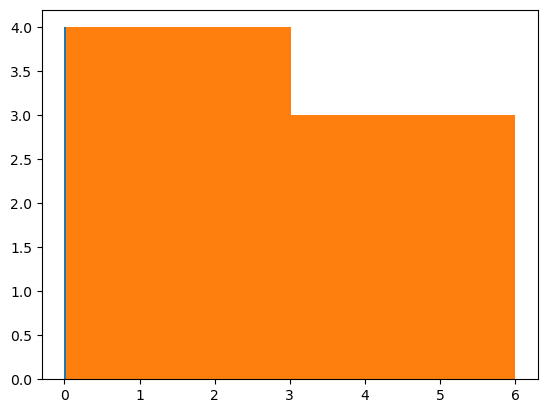

In [10]:
# Para transformar un valor a binario
import matplotlib.pyplot as plt
plt.hist(pd.cut([0.04, 0.3, 4, 5, 6, 0.02, 0.6], bins=2, labels=[0, 1]))

plt.hist([0.04, 0.3, 4, 5, 6, 0.02, 0.6], bins=2)
plt.show()


In [11]:
# Transformamos las características de entrada a un valor binario
X_train_bin = X_train.apply(pd.cut, bins=2, labels=[1, 0])
X_test_bin = X_test.apply(pd.cut, bins=2, labels=[1, 0])

X_train_bin


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
505,1,1,1,1,0,0,1,1,0,0,...,1,1,1,1,0,1,1,1,1,0
359,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
377,1,0,1,1,1,1,1,1,1,1,...,1,0,1,1,1,1,1,1,1,1
157,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
203,1,1,1,1,0,0,1,1,0,0,...,1,0,1,1,0,1,1,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
321,0,1,0,1,1,1,1,1,1,1,...,0,1,1,1,1,1,1,1,1,1
228,1,1,1,1,1,1,1,1,1,1,...,1,0,1,1,1,1,1,1,1,1
177,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,0,1,1
118,1,1,1,1,0,0,1,1,0,1,...,1,1,1,1,0,1,0,0,1,1


In [12]:
# Instanciamos el modelo MP
mp_neurona = MPNeuron()
# Encontramos el threshold óptimo
mp_neurona.fit(X_train_bin.to_numpy(), y_train)
# Threshold óptimo seleccionado
mp_neurona.threshold


28

In [13]:
# Realizamos la predicción para los datos de prueba
Y_pred = mp_neurona.predict(X_test_bin.to_numpy())


In [14]:
Y_pred


array([False,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True, False, False,  True,  True,  True, False,
        True, False, False, False, False,  True, False, False,  True,
       False,  True,  True,  True, False, False, False,  True, False,
       False,  True, False, False,  True, False,  True,  True,  True,
        True,  True, False,  True, False, False, False,  True, False,
        True,  True, False, False, False,  True, False,  True, False,
       False,  True,  True, False,  True, False,  True, False, False,
        True, False,  True, False, False, False,  True, False,  True,
       False,  True, False,  True, False,  True, False, False, False,
        True, False, False, False,  True,  True, False, False, False,
        True, False,  True, False, False,  True,  True,  True, False,
       False,  True, False,  True, False, False, False, False, False,
       False, False, False,  True, False, False,  True,  True,  True,
        True,  True,

In [15]:
# Calculamos la exactitud de nuestra predicción
accuracy_score(y_test, Y_pred)


0.8041958041958042